Cell 1 — Setup Paths & Check Tiles

In [ ]:
import os

TILES_DIR  = '/kaggle/input/datasets/mdafsar07/2nd-p2/2nd tiles p2'
CLEAN_DIR  = "/kaggle/working/tiles_clean"
OUTPUT_DIR = "/kaggle/working/output"

for folder in [CLEAN_DIR, OUTPUT_DIR]:
    os.makedirs(folder, exist_ok=True)

slides = [f for f in os.listdir(TILES_DIR) 
          if os.path.isdir(os.path.join(TILES_DIR, f))]
print(f"✅ Slides found: {len(slides)}")

total = 0
for slide in sorted(slides):
    n = len([f for f in os.listdir(f"{TILES_DIR}/{slide}") 
             if f.endswith('.png')])
    total += n

print(f"📦 Total tiles: {total:,}")

✅ Slides found: 30
📦 Total tiles: 54,913


Cell 2 — Install packages


In [36]:
!pip install torchstain opencv-python-headless tqdm -q
print("✅ Packages installed")

✅ Packages installed


Cell 3 — Preview reference tile

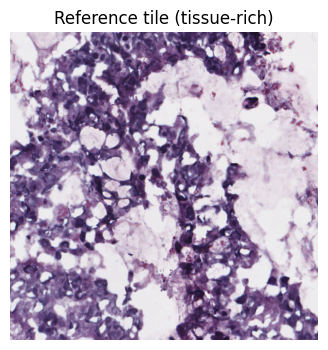

✅ Reference: /kaggle/input/datasets/mdafsar07/2nd-p2/2nd tiles p2/TCGA-C8-A12X-01A-01-BSA_9db0b173-c9c0-45c0-9a43-85296a3031f5/TCGA-C8-A12X-01A-01-BSA.9db0b173-c9c0-45c0-9a43-85296a3031f5 _d2_x12288_y15360_w1024_h1024.png
   White pixels: 29.1%
   Dark pixels:  0.0%
   Mean brightness: 159.1


In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import cv2
import os

def is_good_reference(img_array):
    gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    white_pct = np.sum(gray > 220) / gray.size
    dark_pct  = np.sum(gray < 20)  / gray.size
    return white_pct < 0.3 and dark_pct < 0.1

ref_path = None
for slide in os.listdir(TILES_DIR):
    slide_dir = f"{TILES_DIR}/{slide}"
    if not os.path.isdir(slide_dir):
        continue
    tiles = sorted([t for t in os.listdir(slide_dir) if t.endswith('.png')])
    for tile in tiles:
        path = f"{slide_dir}/{tile}"
        try:
            img = np.array(Image.open(path).convert("RGB"))
            if is_good_reference(img):
                ref_path = path
                break
        except:
            continue
    if ref_path:
        break

ref_img = np.array(Image.open(ref_path).convert("RGB"))
plt.figure(figsize=(4,4))
plt.imshow(ref_img)
plt.title("Reference tile (tissue-rich)")
plt.axis('off')
plt.show()
print(f"✅ Reference: {ref_path}")

gray = cv2.cvtColor(ref_img, cv2.COLOR_RGB2GRAY)
print(f"   White pixels: {np.sum(gray>220)/gray.size*100:.1f}%")
print(f"   Dark pixels:  {np.sum(gray<20)/gray.size*100:.1f}%")
print(f"   Mean brightness: {gray.mean():.1f}")

Cell 4 — Normalize + Quality Filter + Save Clean Tiles (All In One)

In [ ]:
import torchstain
import cv2
from tqdm import tqdm
from PIL import Image
import numpy as np
import os

normalizer = torchstain.normalizers.MacenkoNormalizer(backend='numpy')
normalizer.fit(ref_img)
print("✅ Normalizer fitted")

def is_good_tile(img_array):
    gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    
    if np.sum(gray > 220) / gray.size > 0.85:
        return False, "too_white"
    
    if np.sum(gray < 20) / gray.size > 0.5:
        return False, "too_dark"
    
    if cv2.Laplacian(gray, cv2.CV_64F).var() < 50:
        return False, "too_blurry"
    
    return True, "ok"

all_tiles = []
for slide in os.listdir(TILES_DIR):
    slide_dir = f"{TILES_DIR}/{slide}"
    if not os.path.isdir(slide_dir):
        continue
    for tile in os.listdir(slide_dir):
        if tile.endswith('.png'):
            all_tiles.append((slide, tile))

print(f"📦 Total tiles: {len(all_tiles):,}")

kept = rejected = errors = 0
reasons = {}

for slide, tile in tqdm(all_tiles):
    src     = f"{TILES_DIR}/{slide}/{tile}"
    dst_dir = f"{CLEAN_DIR}/{slide}"
    os.makedirs(dst_dir, exist_ok=True)
    dst     = f"{dst_dir}/{tile}"

    if os.path.exists(dst):
        kept += 1
        continue

    try:
        img    = np.array(Image.open(src).convert("RGB"))
        
        good, reason = is_good_tile(img)
        if not good:
            rejected += 1
            reasons[reason] = reasons.get(reason, 0) + 1
            continue

        try:
            norm_img, _, _ = normalizer.normalize(img)
            save_img = norm_img
        except:
            save_img = img
       
        Image.fromarray(save_img).save(dst)
        kept += 1

    except Exception as e:
        errors += 1

print(f"\n✅ Kept:      {kept:,}")
print(f"❌ Rejected:  {rejected:,}")
print(f"⚠️  Errors:   {errors:,}")
print(f"📊 Keep rate: {kept/(kept+rejected)*100:.1f}%")
print(f"Reasons: {reasons}")

✅ Normalizer fitted
📦 Total tiles: 54,913


100%|██████████| 54913/54913 [50:58<00:00, 17.95it/s]  


✅ Kept:      10,301
❌ Rejected:  44,612
⚠️  Errors:   0
📊 Keep rate: 18.8%
Reasons: {'too_white': 44172, 'too_blurry': 440}


Cell 5 — Create Tile Manifest CSV

In [39]:
import pandas as pd

records = []
for slide in os.listdir(CLEAN_DIR):
    slide_dir = f"{CLEAN_DIR}/{slide}"
    if not os.path.isdir(slide_dir):
        continue
    for tile in os.listdir(slide_dir):
        if tile.endswith('.png'):
            parts = slide.split("_")
            patient_id = f"{parts[0]}-{parts[1]}-{parts[2]}" \
                         if len(parts) >= 3 else slide
            records.append({
                'patient_id' : patient_id,
                'slide_name' : slide,
                'tile_name'  : tile,
                'tile_path'  : f"{CLEAN_DIR}/{slide}/{tile}"
            })

manifest = pd.DataFrame(records)
manifest.to_csv(f"{OUTPUT_DIR}/tile_manifest.csv", index=False)

print(f"✅ Manifest saved!")
print(f"   Total tiles:    {len(manifest):,}")
print(f"   Total slides:   {manifest['slide_name'].nunique()}")
print(f"   Total patients: {manifest['patient_id'].nunique()}")
manifest.head()

✅ Manifest saved!
   Total tiles:    10,301
   Total slides:   30
   Total patients: 30


,patient_id,slide_name,tile_name,tile_path
0,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA.1ecefd59-ca14-4b45-a3a...,/kaggle/working/tiles_clean/TCGA-BH-A0H9-01A-0...
1,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA.1ecefd59-ca14-4b45-a3a...,/kaggle/working/tiles_clean/TCGA-BH-A0H9-01A-0...
2,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA.1ecefd59-ca14-4b45-a3a...,/kaggle/working/tiles_clean/TCGA-BH-A0H9-01A-0...
3,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA.1ecefd59-ca14-4b45-a3a...,/kaggle/working/tiles_clean/TCGA-BH-A0H9-01A-0...
4,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA_1ecefd59-ca14-4b45-a3a...,TCGA-BH-A0H9-01A-01-BSA.1ecefd59-ca14-4b45-a3a...,/kaggle/working/tiles_clean/TCGA-BH-A0H9-01A-0...
